# Train CTR-GCN on NTU skeletons (16 classes)
Run the three cells from top to bottom.

**Before the first run**
1. Google Drive folder `MyDrive/Project_DL` must contain: `src/`, `configs/`, the skeleton cache named in `main_config.yaml` (`skeleton_cache_file`, e.g. `data/processed/skeleton_cache_2d13.npz`), `data/processed/splits.csv` (the same two data files the RGB notebook uses; made by `shrink_data.py` / `loaders.py` on your computer).
2. `src/rgb_vs_skeleton/` must hold the current `loaders.py`, `skeleton_format.py`, `model_CTR_GCN.py`, `train_RGB.py` and `train_skeleton.py`.
3. In Colab: **Runtime → Change runtime type → T4 GPU**.
4. In Colab: key icon on the left → secret `WANDB_API_KEY` → switch on notebook access.

In [5]:
# ============ 1. SETUP: Google Drive, packages, wandb key, data files, GPU ============
import os, sys
from pathlib import Path

import torch
from google.colab import drive, userdata

drive.mount("/content/drive")

PROJECT = Path("/content/drive/MyDrive/Project_DL")   # <- the folder you uploaded to Google Drive
EXP = "exp2"                                           # <- which yaml in configs/experiments/skeleton_experiments/ to use

os.chdir(PROJECT)                                      # all paths in the yaml files are relative to this folder
sys.path.insert(0, str(PROJECT / "src/rgb_vs_skeleton"))

# packages that Colab does not have (torch and matplotlib are already installed)
!pip -q install hydra-core wandb ultralytics

# wandb key: stored in Colab under the key icon on the left (name: WANDB_API_KEY), never typed into the notebook
os.environ["WANDB_API_KEY"] = userdata.get("WANDB_API_KEY")

# the skeleton model needs only two small data files (no videos, no .skeleton text files)
from omegaconf import OmegaConf
cfg = OmegaConf.load("configs/main_config.yaml")
for needed in [cfg.skeleton_cache_file, cfg.split_file, f"configs/experiments/skeleton_experiments/{EXP}.yaml"]:
    if not Path(needed).exists():
        raise FileNotFoundError(f"{needed} is missing on Google Drive (see the list at the top of the notebook)")
    print(f"found {needed}  ({Path(needed).stat().st_size / 1024**2:.1f} MB)")

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("NO GPU: choose Runtime -> Change runtime type -> T4 GPU, then run this cell again")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
found data/processed/skeleton_cache_2d13.npz  (110.5 MB)
found data/processed/splits.csv  (0.4 MB)
found configs/experiments/skeleton_experiments/exp2.yaml  (0.0 MB)
GPU: Tesla T4


### This is the yolo11s-pose model for estimating poses on the HMDB1 dataset, run once

In [ ]:
#!python src/rgb_vs_skeleton/pose_estimation.py            # estimate + select + report

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
[estimate] loading yolo11s-pose.pt on the GPU
[estimate] drink        164 clips in 94 s (8.6 ms per frame in the pose model)
[estimate] eat          108 clips in 59 s (7.8 ms per frame in the pose model)
[estimate] brush_hair   103 clips in 76 s (9.4 ms per frame in the pose model)
[estimate] pick         106 clips in 71 s (8.9 ms per frame in the pose model)
[estimate] throw        102 clips in 64 s (9.1 ms per frame in the pose model)
[estimate] sit          142 clips in 80 s (8.0 ms per frame in the pose model)
[estimate] stand        154 clips in 89 s (8.1 ms per frame in the pose model)
[estimate] clap         130 clips in 81 s (9.6 ms per frame in the pose model)
[estimate] wave         104 cl

[skeleton] no .skeleton text files here - using the existing cache data/processed/skeleton_cache_2d13.npz
[split] loaded data/processed/splits.csv
[skel train]   9200 clips ( 64%)  shape (9200, 2, 64, 13, 2)  | 575 clips per class | 16 performers
[skel val  ]    912 clips (  6%)  shape (912, 2, 64, 13, 2)  | 57 clips per class | 4 performers
[skel test ]   4368 clips ( 30%)  shape (4368, 2, 64, 13, 2)  | 273 clips per class | 20 performers

skeleton format 2d13, one batch: clips (64, 2, 64, 13, 2) = (batch, coordinates, frames, joints, persons), labels [15, 13, 14, 5, 10, 13, 9, 1] ...


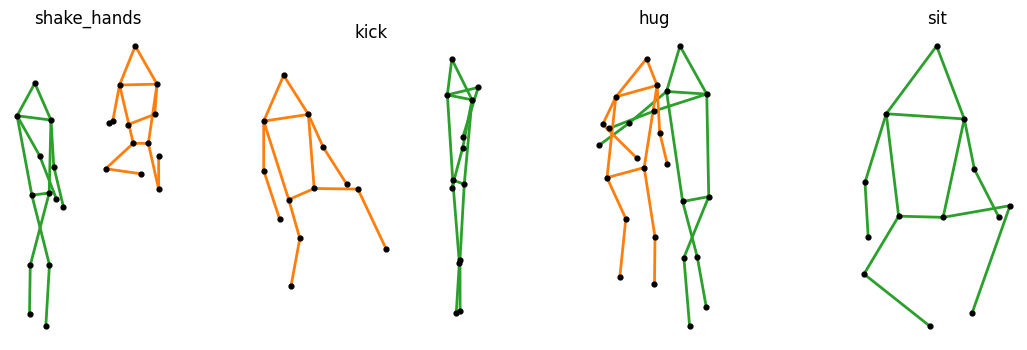

In [6]:
# ============ 2. DATA: build the loaders and look at the input of the model ============
import matplotlib.pyplot as plt
from omegaconf import OmegaConf

from loaders import print_split_summary, skeleton_dataloader
from skeleton_format import FORMATS

cfg = OmegaConf.load("configs/main_config.yaml")
exp = OmegaConf.load(f"configs/experiments/skeleton_experiments/{EXP}.yaml")
actions = [int(c.ntu60) for c in cfg.classes]
class_names = [c.hmdb for c in cfg.classes]

loaders, datasets = skeleton_dataloader(
    skeleton_dir=cfg.processed_skeleton_FOLDER, cache_file=cfg.skeleton_cache_file, actions=actions,
    split_file=cfg.split_file, num_frames=cfg.skeleton_num_frames,
    batch_size=exp.batch_size, num_workers=exp.num_workers, skeleton_format=cfg.skeleton_format)
bones = FORMATS[cfg.skeleton_format]["bones"]
print_split_summary(datasets, "skel")

clips, labels = next(iter(loaders["train"]))
print(f"\nskeleton format {cfg.skeleton_format}, one batch: clips {tuple(clips.shape)} = (batch, coordinates, frames, joints, persons), "
      f"labels {labels[:8].tolist()} ...")

# the middle frame of the first 4 clips; a second person is drawn in orange
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, clip, label in zip(axes, clips, labels):
    frame = clip[:, clip.shape[1] // 2]                      # (xyz, joints, persons)
    for person, colour in enumerate(["tab:green", "tab:orange"]):
        x, y = frame[0, :, person], frame[1, :, person]
        if x.abs().sum() == 0:                               # this person does not exist in the clip
            continue
        for a, b in bones:
            ax.plot([x[a - 1], x[b - 1]], [y[a - 1], y[b - 1]], color=colour, linewidth=2)
        ax.scatter(x, y, s=12, color="black", zorder=3)
    ax.set_title(class_names[label])
    if cfg.skeleton_format == "2d13":
        ax.invert_yaxis()                                    # image coordinates: y grows downwards
    ax.set_aspect("equal")
    ax.axis("off")
plt.show()

In [7]:
# ============ 3. TRAINING: runs src/rgb_vs_skeleton/train_skeleton.py with the chosen experiment yaml ============
# Hyper-parameters: edit configs/experiments/skeleton_experiments/<EXP>.yaml (double-click it in the file browser on the left).
# Progress: watch the lines below, or the live charts at wandb.ai. Stopping this cell is safe: run it again to continue.
!python src/rgb_vs_skeleton/train_skeleton.py +exp={EXP}

[config] experiment file: configs/experiments/skeleton_experiments/exp2.yaml  (run name: ctr_gcn_2d_exp2)
[skeleton] no .skeleton text files here - using the existing cache /content/drive/MyDrive/Project_DL/data/processed/skeleton_cache_2d13.npz
[split] loaded /content/drive/MyDrive/Project_DL/data/processed/splits.csv
[data] train 9200 clips, val 912 clips, skeleton format 2d13, clip shape (2, 64, 13, 2), device cuda
[plan] training epochs 1..40 of a 40-epoch schedule | 1,421,184 parameters, all trained from scratch
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: Currently logged in as: milinkovicz (milinkovicz-hong-kong-university-of-science-and-technology) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: ⢿ Waiting for wandb.init()...
wandb: ⣻ Waiting for wandb.init()...
wandb: ⣽ Waiting for wandb.init()...
wandb: ⣾ Waiting for wandb.init()...
wandb: ⣷ setting up run sbbbfdd7 (0.3s)
wandb: ⣯ setting up run sbbb

#### Evaluation on the test set of the NTU dataset, the one trained on. Run once.

In [8]:
!python src/rgb_vs_skeleton/evaluate_skeleton.py +exp=exp2

[evaluate] experiment exp2 -> /content/drive/MyDrive/Project_DL/models/ctr_gcn_2d_exp2/best.pt | device cuda
[skeleton] no .skeleton text files here - using the existing cache /content/drive/MyDrive/Project_DL/data/processed/skeleton_cache_2d13.npz
[split] loaded /content/drive/MyDrive/Project_DL/data/processed/splits.csv
[data] test set: 4368 clips, 20 performers, 16 classes, skeleton format 2d13
[model] 1,421,184 parameters | trained 40 epochs

[1/2] predicting the test set ...
  [  640/4368 clips]  running accuracy 0.941
  [ 1280/4368 clips]  running accuracy 0.934
  [ 1920/4368 clips]  running accuracy 0.934
  [ 2560/4368 clips]  running accuracy 0.926
  [ 3200/4368 clips]  running accuracy 0.927
  [ 3840/4368 clips]  running accuracy 0.930
  [ 4368/4368 clips]  running accuracy 0.929

[2/2] timing one video sample at a time (batch size 1) ...

TEST RESULTS  ctr_gcn_2d_exp2  (CTR-GCN, 4368 clips)
  accuracy        0.9290   (4058 of 4368 correct)
  macro F1        0.9292

  per clas